# Student Performance Analysis

## Step 2: Load and profile

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../data/raw/StudentPerformanceFactors.csv")

In [2]:
df.shape

(6607, 20)

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 6607 entries, 0 to 6606
Data columns (total 20 columns):
 #   Column                      Non-Null Count  Dtype
---  ------                      --------------  -----
 0   Hours_Studied               6607 non-null   int64
 1   Attendance                  6607 non-null   int64
 2   Parental_Involvement        6607 non-null   str  
 3   Access_to_Resources         6607 non-null   str  
 4   Extracurricular_Activities  6607 non-null   str  
 5   Sleep_Hours                 6607 non-null   int64
 6   Previous_Scores             6607 non-null   int64
 7   Motivation_Level            6607 non-null   str  
 8   Internet_Access             6607 non-null   str  
 9   Tutoring_Sessions           6607 non-null   int64
 10  Family_Income               6607 non-null   str  
 11  Teacher_Quality             6529 non-null   str  
 12  School_Type                 6607 non-null   str  
 13  Peer_Influence              6607 non-null   str  
 14  Physical_Activity  

In [4]:
df.isna().sum()

Hours_Studied                  0
Attendance                     0
Parental_Involvement           0
Access_to_Resources            0
Extracurricular_Activities     0
Sleep_Hours                    0
Previous_Scores                0
Motivation_Level               0
Internet_Access                0
Tutoring_Sessions              0
Family_Income                  0
Teacher_Quality               78
School_Type                    0
Peer_Influence                 0
Physical_Activity              0
Learning_Disabilities          0
Parental_Education_Level      90
Distance_from_Home            67
Gender                         0
Exam_Score                     0
dtype: int64

In [5]:
df.describe()

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Tutoring_Sessions,Physical_Activity,Exam_Score
count,6607.000000,6607.000000,6607.00000,6607.000000,6607.000000,6607.000000,6607.000000
mean,19.975329,79.977448,7.02906,75.070531,1.493719,2.967610,67.235659
std,5.990594,11.547475,1.46812,14.399784,1.230570,1.031231,3.890456
min,1.000000,60.000000,4.00000,50.000000,0.000000,0.000000,55.000000
25%,16.000000,70.000000,6.00000,63.000000,1.000000,2.000000,65.000000
50%,20.000000,80.000000,7.00000,75.000000,1.000000,3.000000,67.000000
75%,24.000000,90.000000,8.00000,88.000000,2.000000,4.000000,69.000000
max,44.000000,100.000000,10.00000,100.000000,8.000000,6.000000,101.000000


## Step 3: Statistical summary (distributions)

In [6]:
# Compute distribution stats for the three key numeric columns
for col in ["Exam_Score", "Hours_Studied", "Attendance"]:
    print(col)
    print("mean:", df[col].mean())
    print("median:", df[col].median())
    print("std:", df[col].std())
    print("skew:", df[col].skew())
    print()

Exam_Score
mean: 67.23565914938702
median: 67.0
std: 3.890455781261732
skew: 1.6448082853982677

Hours_Studied
mean: 19.975329196306948
median: 20.0
std: 5.9905943365787415
skew: 0.013498908859762987

Attendance
mean: 79.97744816104132
median: 80.0
std: 11.547474961482814
skew: 0.013665859547014896



## Step 4: Charts 1 and 2, distributions

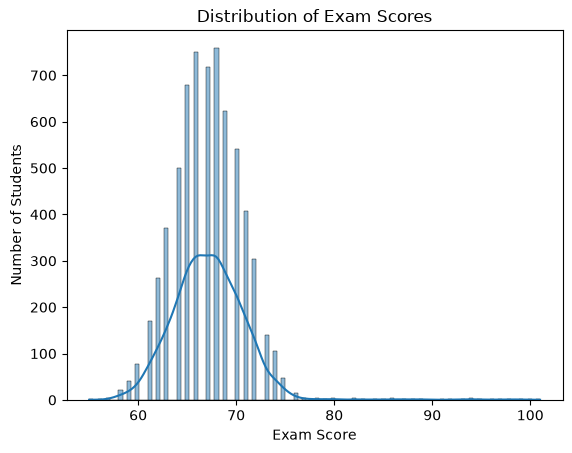

In [7]:
fig, ax = plt.subplots()
sns.histplot(df["Exam_Score"], kde=True, ax=ax)
ax.set_title("Distribution of Exam Scores")
ax.set_xlabel("Exam Score")
ax.set_ylabel("Number of Students")
fig.savefig("../charts/01_exam_score_distribution.png", dpi=150, bbox_inches="tight")

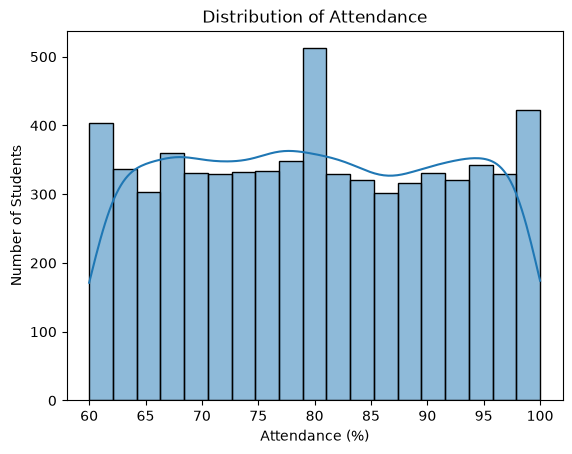

In [8]:
fig, ax = plt.subplots()
sns.histplot(df["Attendance"], kde=True, ax=ax)
ax.set_title("Distribution of Attendance")
ax.set_xlabel("Attendance (%)")
ax.set_ylabel("Number of Students")
fig.savefig("../charts/02_attendance_distribution.png", dpi=150, bbox_inches="tight")

## Step 5: Sampling differences

In [9]:
# Compare sample means for small vs large samples (sampling variability)
np.random.seed(42)
population_mean = df["Exam_Score"].mean()

small_sample_means = [df["Exam_Score"].sample(30).mean() for _ in range(20)]
large_sample_means = [df["Exam_Score"].sample(500).mean() for _ in range(20)]

print("Population mean:", population_mean)
print("Small samples (n=30) range:", min(small_sample_means), "to", max(small_sample_means))
print("Large samples (n=500) range:", min(large_sample_means), "to", max(large_sample_means))

Population mean: 67.23565914938702
Small samples (n=30) range: 66.46666666666667 to 69.3
Large samples (n=500) range: 67.002 to 67.514


## Step 6: Correlation analysis

In [10]:
numeric_cols = ["Hours_Studied", "Attendance", "Sleep_Hours", "Previous_Scores", "Exam_Score"]
corr_matrix = df[numeric_cols].corr()
corr_matrix

,Hours_Studied,Attendance,Sleep_Hours,Previous_Scores,Exam_Score
Hours_Studied,1.000000,-0.009908,0.010977,0.024846,0.445455
Attendance,-0.009908,1.000000,-0.015918,-0.020186,0.581072
Sleep_Hours,0.010977,-0.015918,1.000000,-0.021750,-0.017022
Previous_Scores,0.024846,-0.020186,-0.021750,1.000000,0.175079
Exam_Score,0.445455,0.581072,-0.017022,0.175079,1.000000


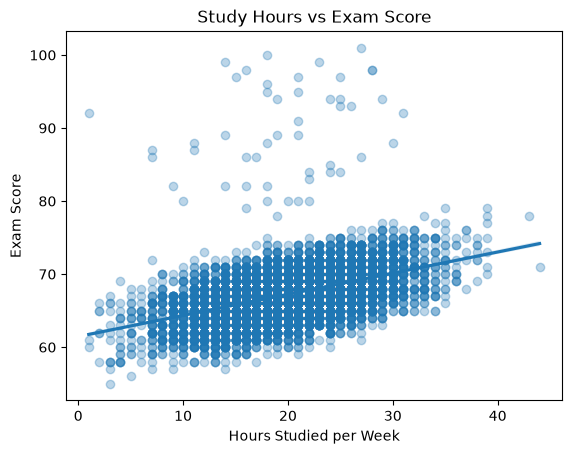

In [11]:
fig, ax = plt.subplots()
sns.regplot(data=df, x="Hours_Studied", y="Exam_Score", scatter_kws={"alpha": 0.3}, ax=ax)
ax.set_title("Study Hours vs Exam Score")
ax.set_xlabel("Hours Studied per Week")
ax.set_ylabel("Exam Score")
fig.savefig("../charts/03_study_hours_vs_score.png", dpi=150, bbox_inches="tight")

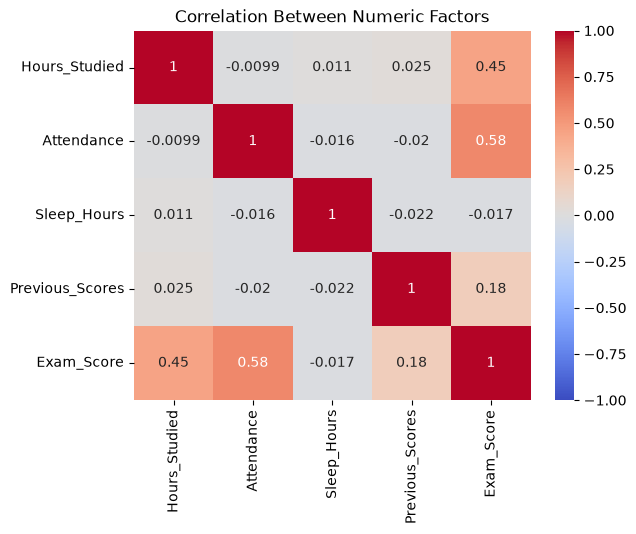

In [12]:
fig, ax = plt.subplots()
sns.heatmap(corr_matrix, annot=True, cmap="coolwarm", vmin=-1, vmax=1, ax=ax)
ax.set_title("Correlation Between Numeric Factors")
fig.savefig("../charts/04_correlation_heatmap.png", dpi=150, bbox_inches="tight")